<a href="https://colab.research.google.com/github/emilybrtt/projeto-machine-learning/blob/main/aps_machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto de Machine Learning

**Docente:** Humberto Sandman

**Equipe:**

Emily Britto — *emilybg@al.insper.edu.br*

Gabriel Chaves Aguiar — *gabrielca5@al.insper.edu.br*


## CHECKLIST


Tarefas básicas de EDA:

1. Carregamento e inspeção inicial dos dados:[OK]

    - Explicar cada feature do dataset. [OK]
    - Verificar o número de instâncias e features. [OK]
    - Identificar tipos de dados (numéricos, categóricos).[OK]
    - Detectar valores ausentes e inconsistências.[OK]
    - Verificar se há desbalanceamento de classes.[OK]
    - Realizar a separação dos dados em conjuntos de treino e teste, quando necessário.[OK]

2. Análise univariada:

    - Calcular estatísticas descritivas (média, mediana, desvio padrão) de todas as variáveis numéricas.[OK]
    - Criar histogramas, boxplots e/ou violinos para variáveis numéricas (máximo 3).[OK]
    - Para variáveis categóricas: calcular frequências e criar gráficos de barras (máximo 3).[OK]

3. Análise bivariada e multivariada:

    - Analisar correlações entre variáveis numéricas usando matrizes de correlação e scatter plots (máximo 3).[OK]
    - Analisar relações entre variáveis categóricas e o target __'income'__ usando gráficos de barras ou tabelas de contingência (máximo 3).[X] (Outro Dataset)
    - Analisar relações entre variáveis numéricas e categóricas usando boxplots conjuntos (máximo 3).[OK]

4. Pré-processamento para modelagem:

    - Escolher e justificar estratégia para lidar com valores ausentes (remoção, imputação).[OK]
    - Escolher e justificar estratégia para lidar com outliers (remoção, transformação).[OK]
    - Escolher e justificar estratégia para encoding de variáveis categóricas (one-hot encoding, label encoding).[OK]
    - Escolher e justificar estratégia para normalização ou padronização de variáveis numéricas (Min-Max Scaling, Standardization, etc.).[OK]
    - Nas variáveis numéricas, aplicar uma técnica de redução de dimensionalidade, como PCA, para visualizar a estrutura dos dados e identificar possíveis agrupamentos ou padrões.[OK]
    - Analisar os resultados da redução de dimensionalidade para obter insights sobre a separabilidade das classes e a importância das features.[OK]
    - Construir um pipeline de pré-processamento (utilizando Pipeline e ColumnTransformer do sklearn) que inclua as etapas acima, garantindo que seja aplicável para as fases de modelagem subsequentes.[OK]

5. Documentação e apresentação:

    - Todos os requisitos do projeto explicitados em cada ponto acima, assim como todas as figuras produzidas e decisões tomadas, devem ser justificados de maneira objetiva.[OK]
    - As visualizações produzidas devem ser claras e informativas com títulos, rótulos e legendas adequados.[OK]
    - Preparar um relatório que resuma os principais achados e as estratégias propostas para a modelagem.[OK]
    - O código deve ser bem organizado, com comentários explicativos para cada etapa.[OK]
    - O grupo deve justificar todas as escolhas de pré-processamento com base nos achados da EDA, garantindo que as estratégias propostas sejam adequadas para os desafios identificados no dataset.[OK]
    - Python obrigatório, utilizando as bibliotecas  Pandas, NumPy, Matplotlib, Seaborn e Scikit-learn.[OK]

### 1. Carregamento e inspeção inicial dos dados:

In [ ]:
import kagglehub
import pandas as pd

# importação do Dataset
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")

df = pd.read_csv(f'{path}/healthcare-dataset-stroke-data.csv')

display(df.head())

100%|██████████| 67.4k/67.4k [00:00<00:00, 14.6MB/s]

Extracting files...


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Informações gerais do DF
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


Podemos verificar que temos **12** colunas, com cerca de 5.100 linhas.

Logo aqui, podemos notar a presença de possíveis colunas booleanas, principalmente ao observar **heart_disease** ou **hypertension**, que estão classificadas como **int64**. Não faz muito sentido quantificar essas características dessa maneira.

Um detalhe interessante é o uso de memória. Posteriormente, vamos comparar nosso dataset de treino com essa base e veremos uma diferença interessante.

In [ ]:
# valores únicos das variáveis categóricas
categoricas = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
    "stroke"
]

df[categoricas].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   gender          5110 non-null   object
 1   hypertension    5110 non-null   int64 
 2   heart_disease   5110 non-null   int64 
 3   ever_married    5110 non-null   object
 4   work_type       5110 non-null   object
 5   Residence_type  5110 non-null   object
 6   smoking_status  5110 non-null   object
 7   stroke          5110 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 319.5+ KB


Esse resultado demonstra a importância de uma análise criteriosa. Vemos que alguns dados categóricos (rotulados assim após interpretarmos as colunas) possuem valores inteiros, que normalmente são considerados quantitativos.

In [ ]:
# VALORES AUSENTES

# NaN
# Trataremos essas faltas posteriormente!
missing = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(2)
})

display(missing[missing["quantidade"] > 0])

# smoking_status
unknown_count = (df["smoking_status"] == "Unknown").sum()
unknown_pct = (df["smoking_status"] == "Unknown").mean() * 100

print(f"'Unknown' em smoking_status: {unknown_count}")
print(f"Percentual: {unknown_pct:.2f}%")

,quantidade,percentual
bmi,201,3.93


'Unknown' em smoking_status: 1544
Percentual: 30.22%


In [ ]:
# INVESTIGANDO DUPLICATAS
"""Duplicatas podem afetar nosso treinamento, afinal, não faz sentido ter o mesmo dado mais
de uma vez"""

print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"IDs duplicados: {df['id'].duplicated().sum()}")

print(f"Ô coisa boa!")

Linhas duplicadas: 0
IDs duplicados: 0
Ô coisa boa!


In [ ]:
# VARIAVEIS NUMERICAS
"""Puramente números"""

numericos = ["age", "avg_glucose_level", "bmi"]
df[numericos].info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                5110 non-null   float64
 1   avg_glucose_level  5110 non-null   float64
 2   bmi                4909 non-null   float64
dtypes: float64(3)
memory usage: 119.9 KB


In [ ]:
df[numericos].describe()


,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


In [ ]:
# ANALISANDO O TARGET

target_count = df["stroke"].value_counts().sort_index()
target_pct = df["stroke"].value_counts(normalize=True).sort_index() * 100 # pega proporção de cada valor em proporções em vez da quantidade absoluta e ordena pelo índice e transgorma em pct

distribuicao_target = pd.DataFrame({
"quantidade": target_count,
"percentual": target_pct.round(2)
})

distribuicao_target.index = ["Sem AVC", "Com AVC"]

display(distribuicao_target)

# Aqui precisamos nos atentar bem! Vemos que apenas 4,87% dos dados temos como AVC
# Isso faz com que nós nao tenhamos brecha para fazer uma divisão dos dados de qualquer jeito
# senão podemos enviesar nosso modelo!

,quantidade,percentual
Sem AVC,4861,95.13
Com AVC,249,4.87


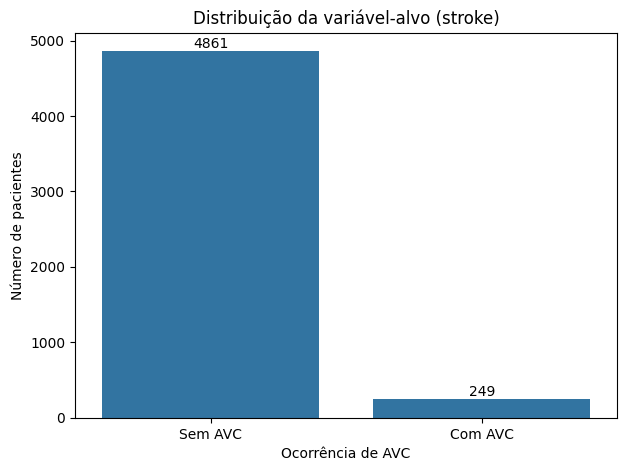

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="stroke"
)

plt.title("Distribuição da variável-alvo (stroke)")
plt.xlabel("Ocorrência de AVC")
plt.ylabel("Número de pacientes")
plt.xticks([0, 1], ["Sem AVC", "Com AVC"])

# add quantidade sobre as barras
for container in ax.containers:
    ax.bar_label(container)

plt.show()



### Interpretando os Dados
Podemos ver uma série de colunas, mas o problema é que muitas são categóricas. Precisamos interpretar cada uma delas para pensar em como transformá-las, deixando de ser estritamente categóricas.

#### (1) Colunas Binárias:
Consistem em colunas de 'sim' ou 'não', que podem ser facilmente substituídas por valores numéricos binários (0 ou 1).
* `hypertension`
* `heart_disease`

#### (2) Colunas Escalonáveis (Standardization):
Nesse caso, ocorre a subtração da média e a divisão pelo desvio padrão. Com isso, é possível existirem valores negativos.
* `age` (Alteramos para Standard para facilitar o PCA)
* `avg_glucose_level`
* `bmi` (Neste caso, precisamos realizar um `SimpleImputer()` para preencher alguns valores faltantes, utilizando a **mediana** como valor de preenchimento)

#### (3) Colunas One-Hot Encoder:
São colunas que possuem mais de duas categorias possíveis, o que pode ser verificado usando `df.unique()`.

O One-Hot Encoder é uma técnica para representar essas diferentes categorias em novas colunas binárias, onde cada uma indica a presença ou ausência daquele valor.
`ever_married` e `Residence_type` também entram aqui, pois não existe uma ordem natural entre suas categorias.

**Exemplo:**
A coluna `work_type` possui as seguintes categorias: `['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']`.
Ao aplicarmos o `OneHotEncoder()`, passamos a ter novas colunas, como:
* `work_type_Govt_job`
* `work_type_Never_worked`
* `work_type_Private`
* `work_type_Self-employed`
* `work_type_children`

Aplicaremos o One-Hot Encoder nas seguintes colunas:
* `work_type`
* `smoking_status`
* `gender`
* `ever_married`
* `Residence_type`

No caso de `smoking_status`, mantivemos `Unknown` como uma categoria própria. Analisando melhor, vemos que esse valor aparece em aproximadamente 30% dos dados de treino, então imputá-lo pela moda atribuiria artificialmente um status de tabagismo a muitos pacientes.

#### (4) ID:
Removemos a coluna `id`, pois era apenas um identificador sem valor preditivo para a análise.

## Divisão entre Treino e Teste

A divisão foi feita com estratificação para mantermos as proporções entre os casos com e sem AVC, já que a variável-alvo tem uma incidência bem baixa dentro do dataset (vamos explorar isso mais a fundo futuramente).

In [ ]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=["stroke", "id"]) # separação entre features e target
y = df["stroke"] # separamos o que queremos prever


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

df_train = X_train.copy() # só pra facilitar nossa vida na hora de explorar
df_train["stroke"] = y_train

In [ ]:
print(f"Dataset completo: {len(df)} observações")
print(f"Treino: {len(X_train)} observações ({len(X_train) / len(df) * 100:.1f}%)")
print(f"Teste: {len(X_test)} observações ({len(X_test) / len(df) * 100:.1f}%)")

comparacao = pd.DataFrame({
    "Dataset completo (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Treino (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Teste (%)": y_test.value_counts(normalize=True).sort_index() * 100
}).round(2)

comparacao.index = ["Sem AVC", "Com AVC"]

display(comparacao)

Dataset completo: 5110 observações
Treino: 4088 observações (80.0%)
Teste: 1022 observações (20.0%)


,Dataset completo (%),Treino (%),Teste (%)
Sem AVC,95.13,95.13,95.11
Com AVC,4.87,4.87,4.89


## 2. Análise univariada

In [ ]:
# ANÁLISE UNIVARIADA

numericas = [
    "age",
    "avg_glucose_level",
    "bmi"
]

estatisticas = pd.DataFrame({
    "média": df_train[numericas].mean(),
    "mediana": df_train[numericas].median(),
    "desvio padrão": df_train[numericas].std(),
    "mínimo": df_train[numericas].min(),
    "máximo": df_train[numericas].max()
}).round(2)

display(estatisticas)

df_train[numericas].describe().T

,média,mediana,desvio padrão,mínimo,máximo
age,43.35,45.00,22.60,0.08,82.00
avg_glucose_level,106.32,91.94,45.26,55.12,271.74
bmi,28.92,28.00,7.93,10.30,97.60


,count,mean,std,min,25%,50%,75%,max
age,4088.0,43.353288,22.596816,0.08,26.0000,45.000,61.0000,82.00
avg_glucose_level,4088.0,106.317167,45.259652,55.12,77.3125,91.945,114.1975,271.74
bmi,3918.0,28.922180,7.928378,10.30,23.6000,28.000,33.1000,97.60


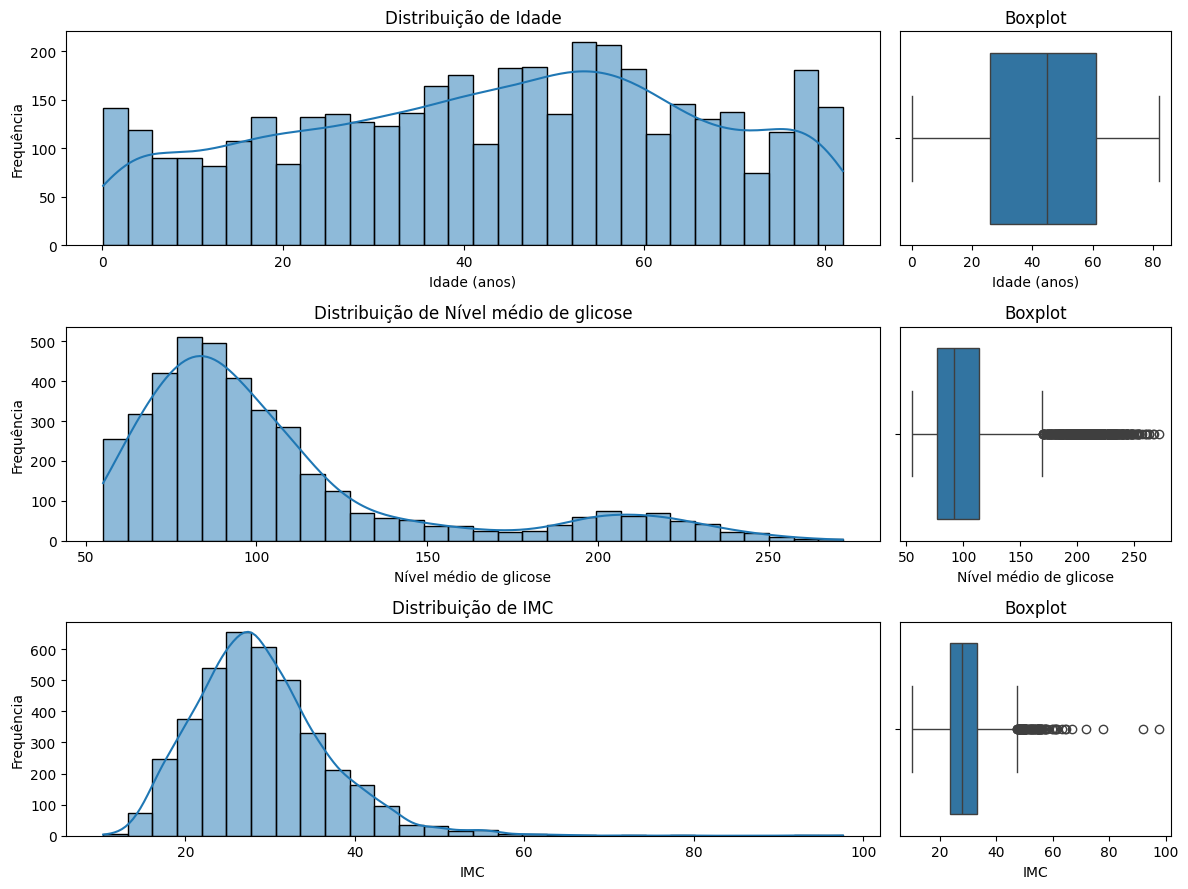

In [ ]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 9),
    gridspec_kw={"width_ratios": [3, 1]}
)

variaveis = [
    ("age", "Idade", "Idade (anos)"),
    ("avg_glucose_level", "Nível médio de glicose", "Nível médio de glicose"),
    ("bmi", "IMC", "IMC")
]

for i, (coluna, titulo, xlabel) in enumerate(variaveis):

    # Histograma
    sns.histplot(
        data=df_train,
        x=coluna,
        bins=30,
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"Distribuição de {titulo}")
    axes[i, 0].set_xlabel(xlabel)
    axes[i, 0].set_ylabel("Frequência")

    # Boxplot
    sns.boxplot(
        data=df_train,
        x=coluna,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title("Boxplot")
    axes[i, 1].set_xlabel(xlabel)
    axes[i, 1].set_ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
def resumo_outliers_iqr(data: pd.DataFrame, colunas: list) -> pd.DataFrame:
    resultados = []

    for coluna in colunas:
        serie = data[coluna].dropna()

        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        outliers = serie[
            (serie < limite_inferior) |
            (serie > limite_superior)
        ]

        resultados.append({
            "variável": coluna,
            "limite inferior": limite_inferior,
            "limite superior": limite_superior,
            "outliers": len(outliers),
            "percentual (%)": len(outliers) / len(serie) * 100
        })

    return pd.DataFrame(resultados).round(2)


resumo_outliers = resumo_outliers_iqr(
    df_train,
    ["age", "avg_glucose_level", "bmi"]
)

display(resumo_outliers)

,variável,limite inferior,limite superior,outliers,percentual (%)
0,age,-26.50,113.50,0,0.0
1,avg_glucose_level,21.98,169.52,503,12.3
2,bmi,9.35,47.35,90,2.3


In [ ]:
def marcar_outlier_iqr(data: pd.DataFrame, coluna: list) -> tuple:
    q1 = data[coluna].quantile(0.25)
    q3 = data[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    return (
        (data[coluna] < limite_inferior) |
        (data[coluna] > limite_superior)
    )

df_train["outlier_glucose"] = marcar_outlier_iqr(
    df_train, "avg_glucose_level"
)

df_train["outlier_bmi"] = marcar_outlier_iqr(
    df_train, "bmi"
)

def comparar_outliers_stroke(data: pd.DataFrame, coluna_outlier: str):
    tabela = (
        data.groupby(coluna_outlier)["stroke"]
        .agg(
            pacientes="count",
            casos_avc="sum",
            taxa_avc="mean"
        )
    )

    tabela["taxa_avc (%)"] = tabela["taxa_avc"] * 100

    return tabela.drop(columns="taxa_avc").round(2)


comparar_outliers_stroke(
  df_train,
  "outlier_glucose"
)


,pacientes,casos_avc,taxa_avc (%)
outlier_glucose,,,
False,3585,133,3.71
True,503,66,13.12


In [ ]:

comparar_outliers_stroke(
    df_train,
    "outlier_bmi"
)

,pacientes,casos_avc,taxa_avc (%)
outlier_bmi,,,
False,3998,196,4.90
True,90,3,3.33


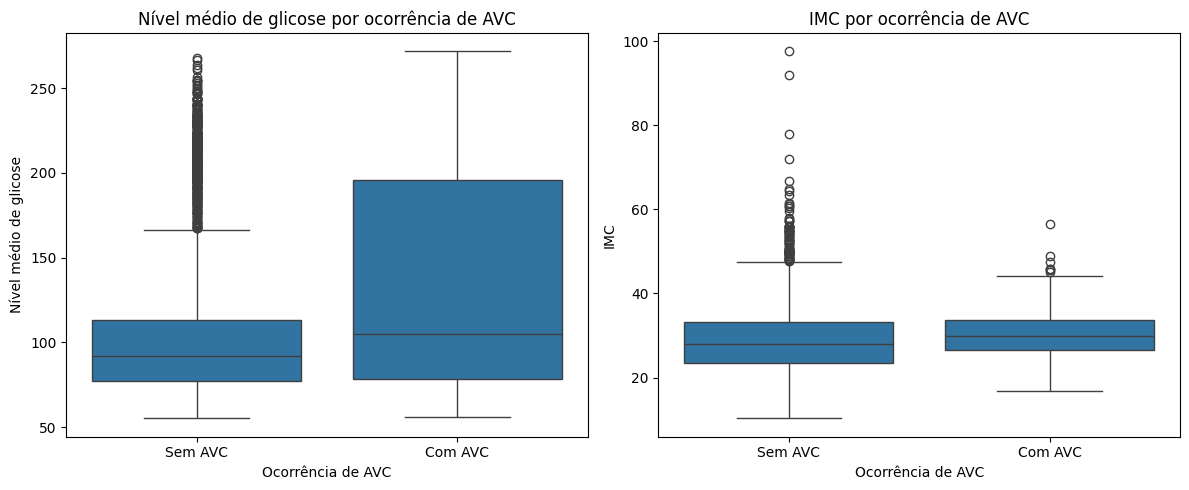

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Glicose
sns.boxplot(
    data=df_train,
    x="stroke",
    y="avg_glucose_level",
    ax=axes[0]
)

axes[0].set_title("Nível médio de glicose por ocorrência de AVC")
axes[0].set_xlabel("Ocorrência de AVC")
axes[0].set_ylabel("Nível médio de glicose")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Sem AVC", "Com AVC"])


# IMC
sns.boxplot(
    data=df_train,
    x="stroke",
    y="bmi",
    ax=axes[1]
)

axes[1].set_title("IMC por ocorrência de AVC")
axes[1].set_xlabel("Ocorrência de AVC")
axes[1].set_ylabel("IMC")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Sem AVC", "Com AVC"])

plt.tight_layout()
plt.show()

In [ ]:
categoricas_univariadas = [
    "smoking_status",
    "work_type",
    "gender"
]

for coluna in categoricas_univariadas:
    frequencia = pd.DataFrame({
        "quantidade": df_train[coluna].value_counts(),
        "percentual (%)": (
            df_train[coluna].value_counts(normalize=True) * 100
        ).round(2)
    })

    print(f"\n{coluna}")
    display(frequencia)


smoking_status


,quantidade,percentual (%)
smoking_status,,
never smoked,1501,36.72
Unknown,1247,30.50
formerly smoked,714,17.47
smokes,626,15.31



work_type


,quantidade,percentual (%)
work_type,,
Private,2332,57.05
Self-employed,667,16.32
children,554,13.55
Govt_job,522,12.77
Never_worked,13,0.32



gender


,quantidade,percentual (%)
gender,,
Female,2395,58.59
Male,1692,41.39
Other,1,0.02


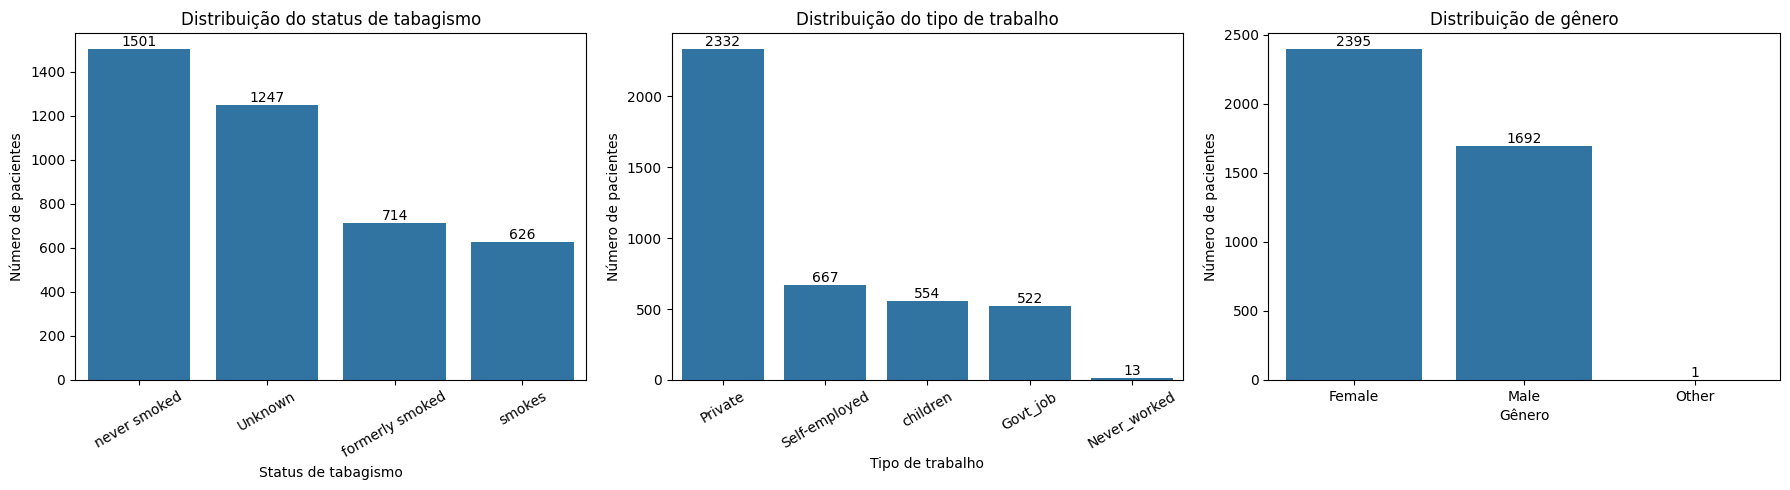

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Smoking status
ordem_smoking = df_train["smoking_status"].value_counts().index
sns.countplot(
    data=df_train,
    x="smoking_status",
    order=ordem_smoking,
    ax=axes[0]
)
axes[0].set_title("Distribuição do status de tabagismo")
axes[0].set_xlabel("Status de tabagismo")
axes[0].set_ylabel("Número de pacientes")
axes[0].tick_params(axis="x", rotation=30)

# Work type
ordem_work = df_train["work_type"].value_counts().index
sns.countplot(
    data=df_train,
    x="work_type",
    order=ordem_work,
    ax=axes[1]
)
axes[1].set_title("Distribuição do tipo de trabalho")
axes[1].set_xlabel("Tipo de trabalho")
axes[1].set_ylabel("Número de pacientes")
axes[1].tick_params(axis="x", rotation=30)

# Gender
ordem_gender = df_train["gender"].value_counts().index
sns.countplot(
    data=df_train,
    x="gender",
    order=ordem_gender,
    ax=axes[2]
)
axes[2].set_title("Distribuição de gênero")
axes[2].set_xlabel("Gênero")
axes[2].set_ylabel("Número de pacientes")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
plt.tight_layout()
plt.show()

In [ ]:
df_train.drop(
    columns=["outlier_glucose", "outlier_bmi"],
    inplace=True
) # essas colunas eram apenas auxiliares

## 3. Análise bivariada e multivariada

,age,avg_glucose_level,bmi
age,1.00,0.23,0.34
avg_glucose_level,0.23,1.00,0.17
bmi,0.34,0.17,1.00


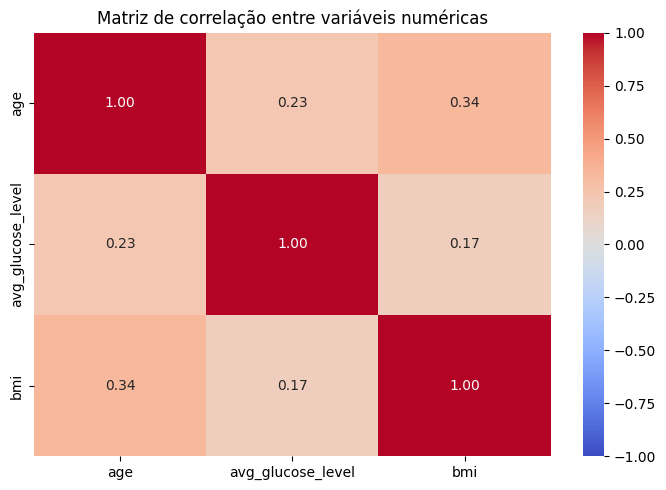

In [ ]:
# ANALISE MULTIVARIADA

numericas = [
    "age",
    "avg_glucose_level",
    "bmi"
]

correlacao = df_train[numericas].corr()

display(correlacao.round(2)) # matriz de correlacao

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

Algumas observações sobre a matriz de correlação:
- Não há nenhuma correlação negativa.
- Nenhuma correlação é muito forte; todas estão relativamente próximas de zero.

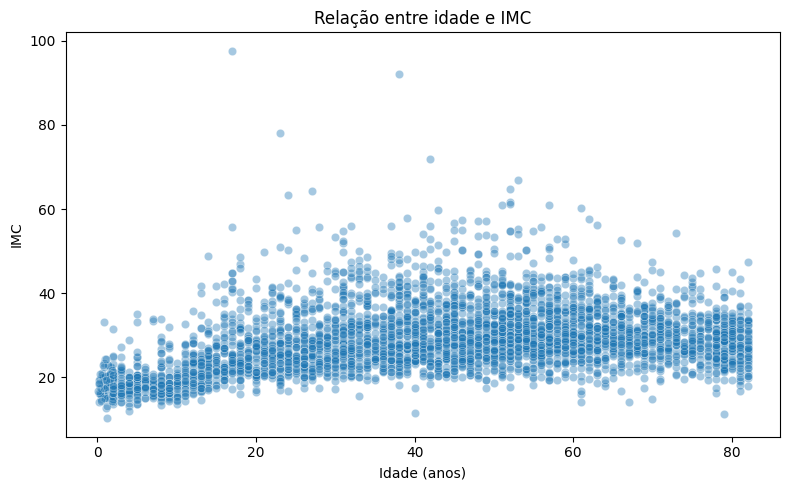

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_train,
    x="age",
    y="bmi",
    alpha=0.4
)

plt.title("Relação entre idade e IMC")
plt.xlabel("Idade (anos)")
plt.ylabel("IMC")

plt.tight_layout()
plt.show()



O IMC tende a aumentar com a idade, principalmente até a fase adulta, mas a relação não é muito forte, o que condiz com o resultado da matriz de correlação.
Depois disso, os valores ficam bem espalhados. Portanto, a idade sozinha não explica muito bem o IMC.

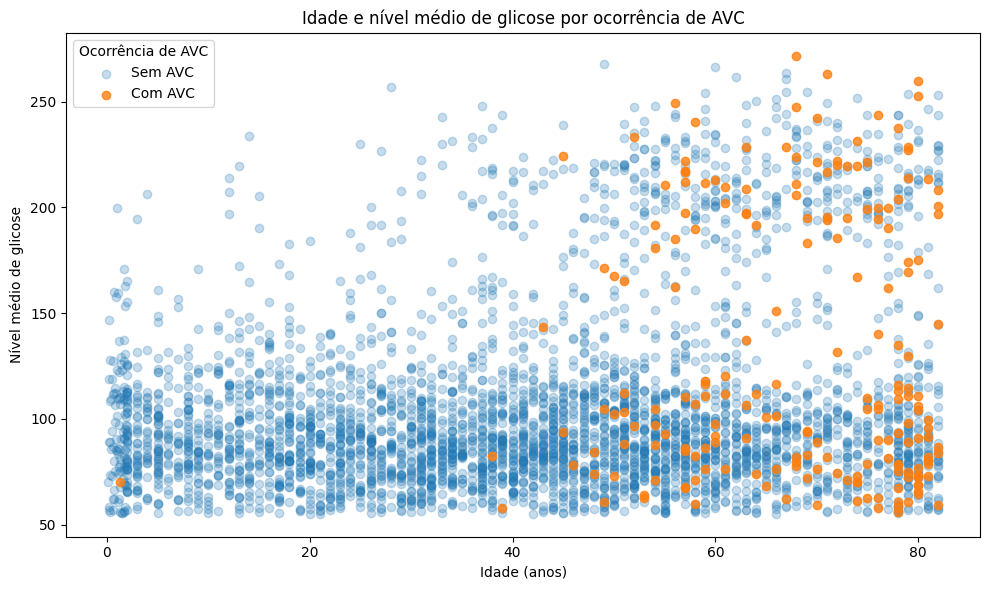

In [ ]:
plt.figure(figsize=(10, 6))

sem_avc = df_train[df_train["stroke"] == 0]
com_avc = df_train[df_train["stroke"] == 1]

plt.scatter(
    sem_avc["age"],
    sem_avc["avg_glucose_level"],
    alpha=0.25,
    label="Sem AVC"
)

plt.scatter(
    com_avc["age"],
    com_avc["avg_glucose_level"],
    alpha=0.8,
    label="Com AVC"
)

plt.title("Idade e nível médio de glicose por ocorrência de AVC")
plt.xlabel("Idade (anos)")
plt.ylabel("Nível médio de glicose")
plt.legend(title="Ocorrência de AVC")

plt.tight_layout()
plt.show()

Os casos de AVC se concentram principalmente nas idades mais avançadas, muitos deles também acompanhados de glicose elevada.
Isso sugere (mas não implica necessariamente) que idade e glicose podem ser características importantes para diferenciar os casos de AVC.

Comparando as idades dos pacientes com e sem AVC para confirmar o padrão visto no gráfico: pacientes com AVC são consideravelmente mais velhos, com uma média de 67 anos, contra 42 anos nos casos sem AVC.

In [ ]:
df_train.groupby("stroke")["age"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

,mean,median,std,min,max
stroke,,,,,
0,42.11,44.0,22.31,0.08,82.0
1,67.66,70.0,11.88,1.32,82.0


In [ ]:
# essa separação por idade tá sendo interessante, vamos agrupar essa galera
faixas = pd.cut(
    df_train["age"],
    bins=[0, 18, 40, 60, float("inf")],
    labels=["0–18", "19–40", "41–60", "60+"],
    include_lowest=True
)

taxa_stroke_idade = (
    df_train
    .assign(faixa_etaria=faixas)
    .groupby("faixa_etaria", observed=False)["stroke"]
    .agg(
        pacientes="count",
        casos_avc="sum",
        taxa_avc="mean"
    )
)

taxa_stroke_idade["taxa_avc (%)"] = (
    taxa_stroke_idade["taxa_avc"] * 100
)

display(
    taxa_stroke_idade
    .drop(columns="taxa_avc")
    .round(2)
)

,pacientes,casos_avc,taxa_avc (%)
faixa_etaria,,,
0–18,725,1,0.14
19–40,1055,2,0.19
41–60,1264,57,4.51
60+,1044,139,13.31


In [ ]:
categoricas = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

for coluna in categoricas:
    tabela = (
        df_train
        .groupby(coluna)["stroke"]
        .agg(
            pacientes="count",
            casos_avc="sum",
            taxa_avc="mean"
        )
    )

    tabela["taxa_avc (%)"] = tabela["taxa_avc"] * 100

    print(f"\n{coluna}")
    display(
        tabela
        .drop(columns="taxa_avc")
        .sort_values("taxa_avc (%)", ascending=False)
        .round(2)
    )


gender


,pacientes,casos_avc,taxa_avc (%)
gender,,,
Male,1692,87,5.14
Female,2395,112,4.68
Other,1,0,0.00



hypertension


,pacientes,casos_avc,taxa_avc (%)
hypertension,,,
1,397,54,13.60
0,3691,145,3.93



heart_disease


...

,pacientes,casos_avc,taxa_avc (%)
work_type,,,
Self-employed,667,55,8.25
Govt_job,522,28,5.36
Private,2332,115,4.93
children,554,1,0.18
Never_worked,13,0,0.00



Residence_type


,pacientes,casos_avc,taxa_avc (%)
Residence_type,,,
Urban,2069,108,5.22
Rural,2019,91,4.51



smoking_status


,pacientes,casos_avc,taxa_avc (%)
smoking_status,,,
formerly smoked,714,56,7.84
smokes,626,34,5.43
never smoked,1501,71,4.73
Unknown,1247,38,3.05


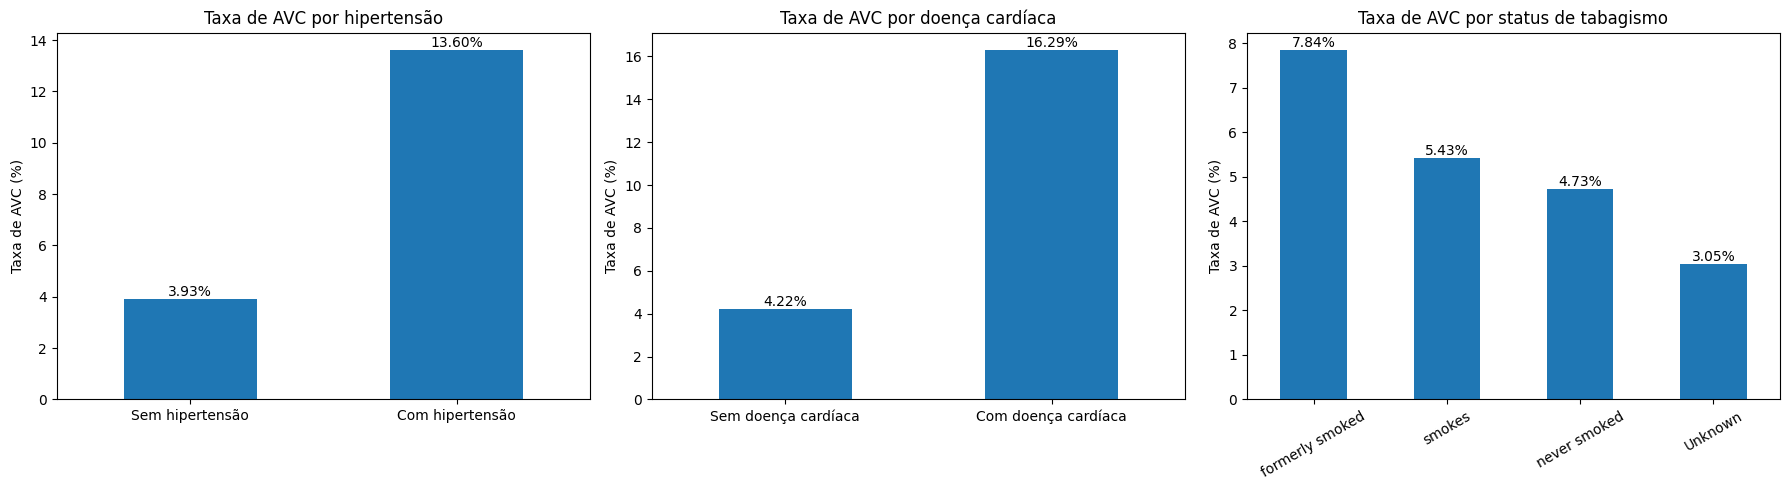

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


# Hipertensão
taxas = (
    df_train.groupby("hypertension")["stroke"]
    .mean()
    .mul(100)
)

taxas.index = ["Sem hipertensão", "Com hipertensão"]

taxas.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Taxa de AVC por hipertensão")
axes[0].set_xlabel("")
axes[0].set_ylabel("Taxa de AVC (%)")
axes[0].tick_params(axis="x", rotation=0)


# Doença cardíaca
taxas = (
    df_train.groupby("heart_disease")["stroke"]
    .mean()
    .mul(100)
)

taxas.index = ["Sem doença cardíaca", "Com doença cardíaca"]

taxas.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Taxa de AVC por doença cardíaca")
axes[1].set_xlabel("")
axes[1].set_ylabel("Taxa de AVC (%)")
axes[1].tick_params(axis="x", rotation=0)


# Tabagismo
ordem_smoking = [
    "formerly smoked",
    "smokes",
    "never smoked",
    "Unknown"
]

taxas = (
    df_train.groupby("smoking_status")["stroke"]
    .mean()
    .mul(100)
    .reindex(ordem_smoking)
)

taxas.plot(
    kind="bar",
    ax=axes[2]
)

axes[2].set_title("Taxa de AVC por status de tabagismo")
axes[2].set_xlabel("")
axes[2].set_ylabel("Taxa de AVC (%)")
axes[2].tick_params(axis="x", rotation=30)


# valores sobre as barras
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%")


plt.tight_layout()
plt.show()

Notamos que pacientes com hipertensão ou doenças cardíacas apresentaram uma taxa de AVC consideravelmente maior do que os pacientes sem essas condições.
Em relação ao tabagismo, o grupo de ex-fumantes (`formerly smoked`) teve a maior taxa de incidência. No entanto, não podemos afirmar que isso ocorreu exclusivamente pelo histórico de tabagismo, já que a idade e outros fatores também podem estar influenciando esse resultado.

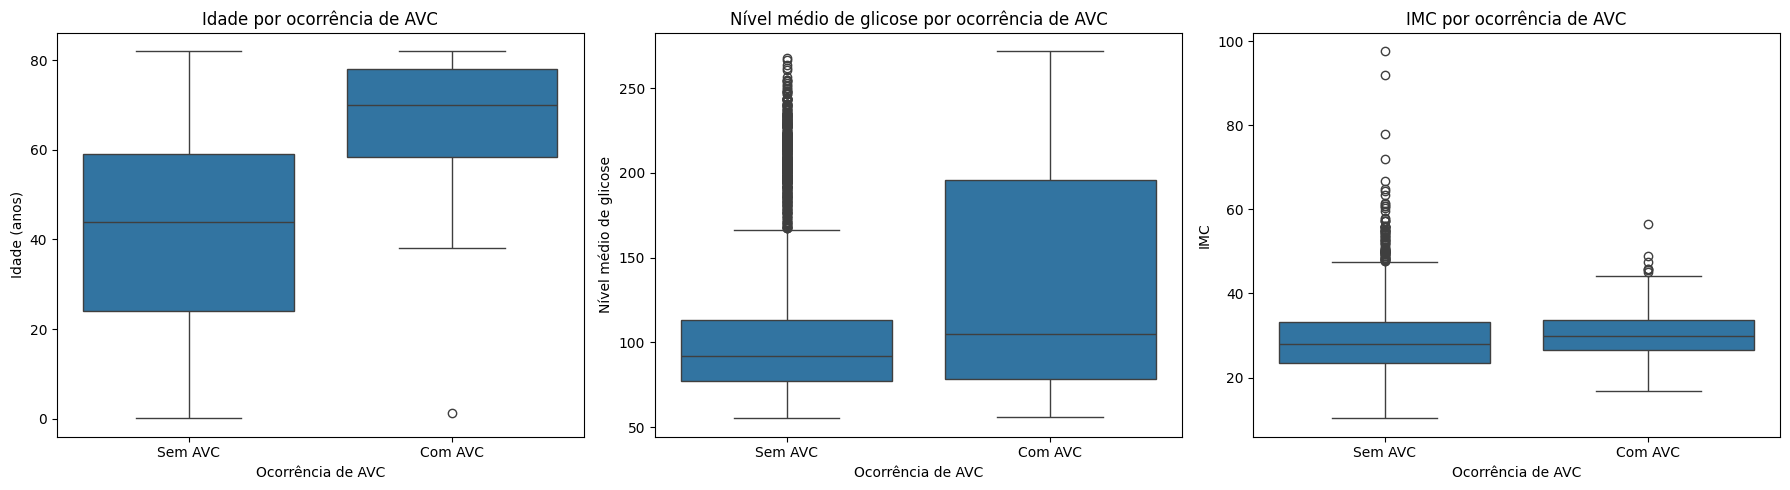

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Idade
sns.boxplot(
    data=df_train,
    x="stroke",
    y="age",
    ax=axes[0]
)

axes[0].set_title("Idade por ocorrência de AVC")
axes[0].set_xlabel("Ocorrência de AVC")
axes[0].set_ylabel("Idade (anos)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Sem AVC", "Com AVC"])


# Glicose
sns.boxplot(
    data=df_train,
    x="stroke",
    y="avg_glucose_level",
    ax=axes[1]
)

axes[1].set_title("Nível médio de glicose por ocorrência de AVC")
axes[1].set_xlabel("Ocorrência de AVC")
axes[1].set_ylabel("Nível médio de glicose")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Sem AVC", "Com AVC"])


# IMC
sns.boxplot(
    data=df_train,
    x="stroke",
    y="bmi",
    ax=axes[2]
)

axes[2].set_title("IMC por ocorrência de AVC")
axes[2].set_xlabel("Ocorrência de AVC")
axes[2].set_ylabel("IMC")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Sem AVC", "Com AVC"])


plt.tight_layout()
plt.show()

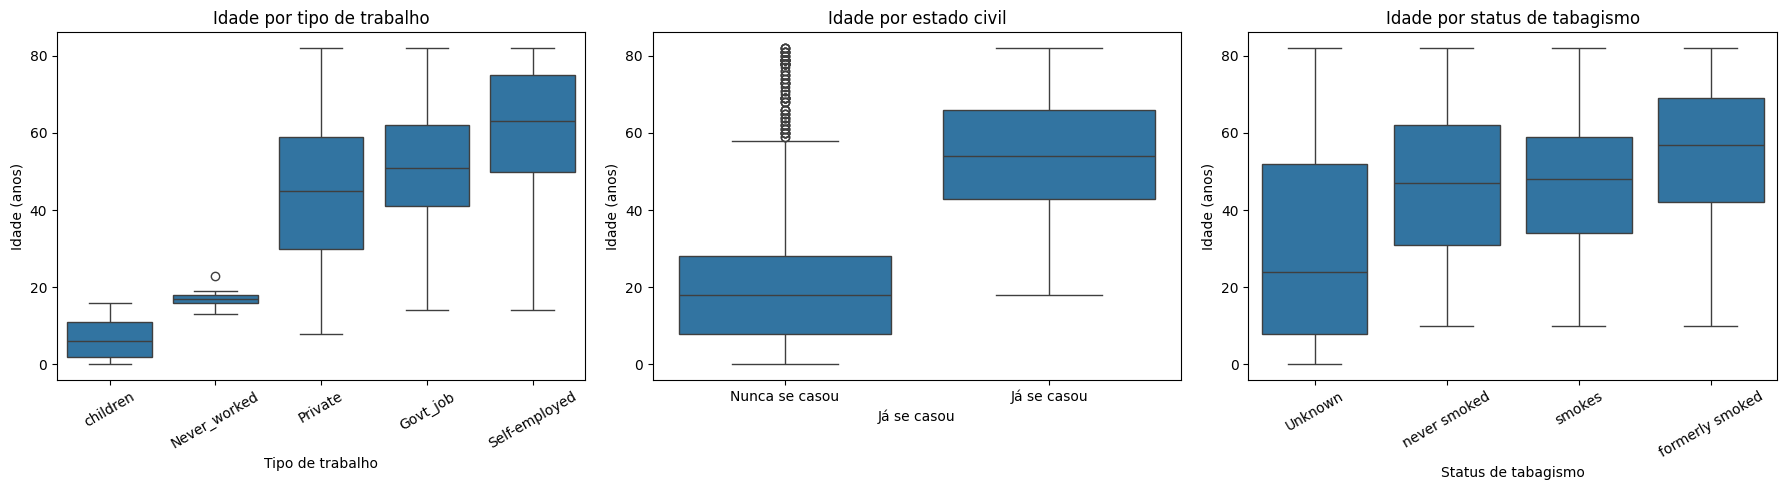

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Idade por tipo de trabalho
work_order = (
    df_train.groupby("work_type")["age"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_train,
    x="work_type",
    y="age",
    order=work_order,
    ax=axes[0]
)

axes[0].set_title("Idade por tipo de trabalho")
axes[0].set_xlabel("Tipo de trabalho")
axes[0].set_ylabel("Idade (anos)")
axes[0].tick_params(axis="x", rotation=30)


# Idade por estado civil
sns.boxplot(
    data=df_train,
    x="ever_married",
    y="age",
    order=["No", "Yes"],
    ax=axes[1]
)

axes[1].set_title("Idade por estado civil")
axes[1].set_xlabel("Já se casou")
axes[1].set_ylabel("Idade (anos)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Nunca se casou", "Já se casou"])


# Idade por status de tabagismo
smoking_order = (
    df_train.groupby("smoking_status")["age"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_train,
    x="smoking_status",
    y="age",
    order=smoking_order,
    ax=axes[2]
)

axes[2].set_title("Idade por status de tabagismo")
axes[2].set_xlabel("Status de tabagismo")
axes[2].set_ylabel("Idade (anos)")
axes[2].tick_params(axis="x", rotation=30)


plt.tight_layout()

# Salva a imagem usada pelo Markdown
plt.savefig(
    "idade_por_categoricas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Aqui, vemos que os pacientes com AVC tendem a ser mais velhos e, geralmente, apresentam níveis de glicose mais altos.
O IMC também é ligeiramente maior no grupo que teve AVC, mas a diferença entre os grupos é bem menor quando comparada à idade e à glicose.

In [ ]:
resumo_numericas_stroke = (
    df_train
    .groupby("stroke")[["age", "avg_glucose_level", "bmi"]]
    .agg(["mean", "median", "std"])
    .round(2)
) # infos pra bater rubrica

display(resumo_numericas_stroke)

age               avg_glucose_level                   bmi         \
         mean median    std              mean  median    std   mean median   
stroke                                                                       
0       42.11   44.0  22.31            105.03   91.65  43.85  28.85  27.95   
1       67.66   70.0  11.88            131.39  104.86  62.13  30.59  29.90   

              
         std  
stroke        
0       7.98  
1       6.40

Redução de dimensionalidade - PCA



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_features = ["age", "avg_glucose_level", "bmi"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# fit apenas no treino
X_num_train = num_pipeline.fit_transform(X_train[num_features])

pca_num = PCA()
Z_num = pca_num.fit_transform(X_num_train)
var = pca_num.explained_variance_ratio_

tabela = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(var))],
    "Variância explicada": var.round(4),
    "Variância acumulada": var.cumsum().round(4),
})
print(tabela)

loadings = pd.DataFrame(
    pca_num.components_.T,
    index=num_features,
    columns=[f"PC{i+1}" for i in range(pca_num.n_components_)],
).round(3)
print(loadings)

  Componente  Variância explicada  Variância acumulada
0        PC1               0.4955               0.4955
1        PC2               0.2833               0.7788
2        PC3               0.2212               1.0000
                     PC1    PC2    PC3
age                0.634 -0.180  0.752
avg_glucose_level  0.500  0.838 -0.220
bmi                0.590 -0.516 -0.621


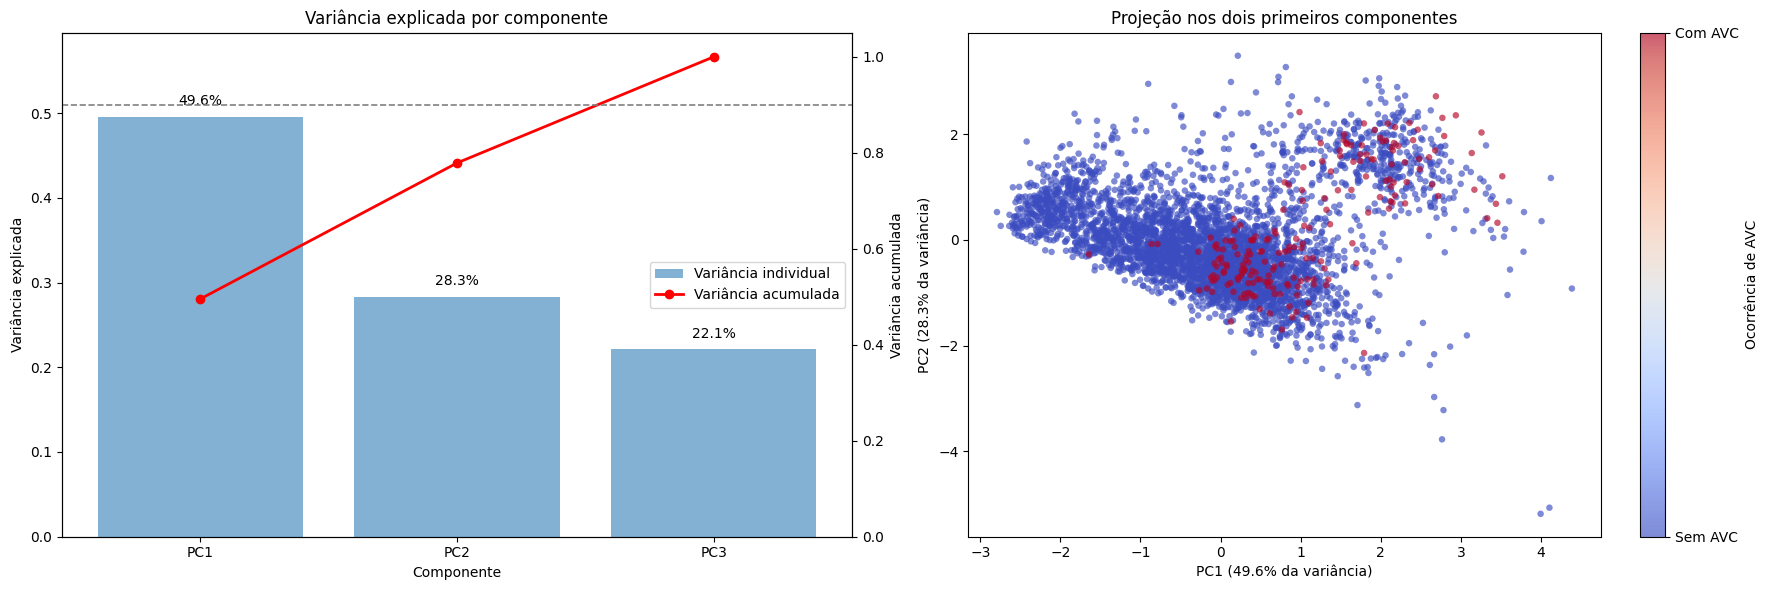

In [ ]:
# Variância acumulada
var_acumulada = np.cumsum(var)
componentes = np.arange(1, len(var) + 1)

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 6)
)

# ============================================================
# Gráfico 1 — Variância explicada
# ============================================================

ax1 = axes[0]

barras = ax1.bar(
    componentes,
    var,
    color="#74A9CF",
    alpha=0.9,
    label="Variância individual"
)

ax1.set_title("Variância explicada por componente")
ax1.set_xlabel("Componente")
ax1.set_ylabel("Variância explicada")
ax1.set_xticks(componentes)
ax1.set_xticklabels(
    [f"PC{i}" for i in componentes]
)
ax1.set_ylim(0, max(var) * 1.20)

# Valores acima das barras
for barra, valor in zip(barras, var):
    ax1.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.01,
        f"{valor:.1%}",
        ha="center",
        va="bottom"
    )

# Segundo eixo para a variância acumulada
ax2 = ax1.twinx()

linha, = ax2.plot(
    componentes,
    var_acumulada,
    color="red",
    marker="o",
    linewidth=2,
    label="Variância acumulada"
)

ax2.axhline(
    y=0.90,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Limite de 90%"
)

ax2.set_ylabel("Variância acumulada")
ax2.set_ylim(0, 1.05)

# Legenda conjunta
elementos = [barras, linha]
rotulos = [
    "Variância individual",
    "Variância acumulada"
]

ax1.legend(
    elementos,
    rotulos,
    loc="center right"
)


# ============================================================
# Gráfico 2 — Projeção nos dois primeiros componentes
# ============================================================

# Converte o target para array
classes = np.asarray(y_train)

# Coloca os pacientes com AVC por cima no gráfico
ordem = np.argsort(classes)

dispersao = axes[1].scatter(
    Z_num[ordem, 0],
    Z_num[ordem, 1],
    c=classes[ordem],
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    alpha=0.65,
    s=22,
    edgecolors="none"
)

axes[1].set_title("Projeção nos dois primeiros componentes")
axes[1].set_xlabel(
    f"PC1 ({var[0]:.1%} da variância)"
)
axes[1].set_ylabel(
    f"PC2 ({var[1]:.1%} da variância)"
)

# Barra de cores com nomes das classes
colorbar = fig.colorbar(
    dispersao,
    ax=axes[1],
    ticks=[0, 1]
)

colorbar.set_label("Ocorrência de AVC")
colorbar.set_ticklabels([
    "Sem AVC",
    "Com AVC"
])

plt.tight_layout()

# Salva a figura para utilização no relatório
plt.savefig(
    "pca_numerico.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_features = ["age", "avg_glucose_level", "bmi"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# fit apenas no treino
X_num_train = num_pipeline.fit_transform(X_train[num_features])

pca_num = PCA()
Z_num = pca_num.fit_transform(X_num_train)
var = pca_num.explained_variance_ratio_

tabela = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(var))],
    "Variância explicada": var.round(4),
    "Variância acumulada": var.cumsum().round(4),
})
print(tabela)

loadings = pd.DataFrame(
    pca_num.components_.T,
    index=num_features,
    columns=[f"PC{i+1}" for i in range(pca_num.n_components_)],
).round(3)
print(loadings)

  Componente  Variância explicada  Variância acumulada
0        PC1               0.4955               0.4955
1        PC2               0.2833               0.7788
2        PC3               0.2212               1.0000
                     PC1    PC2    PC3
age                0.634 -0.180  0.752
avg_glucose_level  0.500  0.838 -0.220
bmi                0.590 -0.516 -0.621


Aplicamos o PCA nas variáveis numéricas para visualizar a estrutura dos dados. O gráfico de variância explicada mostra que a informação está bem distribuída entre os componentes. São necessários cerca de 9 a 10 dos 11 componentes para explicar 90% da variância, o que indica uma baixa redundância entre as variáveis.

Na projeção dos dois primeiros componentes (PC1 x PC2), os pacientes com AVC (em vermelho) aparecem misturados aos pacientes sem AVC (em azul), sem formar um grupo bem separado. Isso demonstra que, nessas duas dimensões, não há uma separação clara entre as classes e também evidencia o desbalanceamento dos dados.

## 4. Pré-processamento para Modelagem
Agora que exploramos nossos dados e entendemos quais variáveis vamos usar e como tratá-las, podemos começar a estruturar o nosso pipeline de processamento.

In [ ]:
# PRE PROCESSAMENTO
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

colunas_numericas = [
    "age",
    "avg_glucose_level",
    "bmi"
] # imputação de valores ausentes ->  padronizar

colunas_categoricas = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
] # one-hot encoding

colunas_binarias_numericas = [
    "hypertension",
    "heart_disease"
] # não precisam de encoding


In [ ]:
# Pipeline numericas
pipeline_numerico = Pipeline([
    ("imputer",
        SimpleImputer(strategy="median") # substitui os ausentes pela mediana
    ),
    ("scaler",
        StandardScaler()  # transforma as vars para média 0 e dp 1
    )
])

# Pipeline categóricas

pipeline_categorico = Pipeline([
    ("one_hot",
        OneHotEncoder(handle_unknown="ignore")
    )
])

In [ ]:

# usando columntransformer pros diferentes pipelines

pre_processador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico,
            colunas_numericas
        ), # numéricas -> imputação + padronização

        (
            "categoricas",
            pipeline_categorico,
            colunas_categoricas
        ), # categóricas -> One-Hot Encoding

        (
            "binarias",
            "passthrough",
            colunas_binarias_numericas
        ) # binárias já numéricas n precisa mexer

    ]
)

In [ ]:
X_train[num_features].corr(method="spearman")
X_train.groupby("work_type")["age"].median()
X_train.groupby("ever_married")["age"].median()
pre_processador.fit_transform(X_train).shape

(4088, 21)

In [ ]:
X_train[num_features].corr(method="spearman")
X_train.groupby(["work_type", "ever_married"])["age"].median()

work_type      ever_married
Govt_job       No              37.0
               Yes             53.0
Never_worked   No              17.0
Private        No              24.0
               Yes             52.0
Self-employed  No              45.0
               Yes             64.0
children       No               6.0
Name: age, dtype: float64

In [ ]:
X_train_transformado = pre_processador.fit_transform(X_train)
X_test_transformado = pre_processador.transform(X_test) # note: transform, não fit_transform

In [ ]:
print("Formato original do treino:")
print(X_train.shape)

print("\nFormato após preparo:")
print(X_train_transformado.shape) # só pra garantir q não perdemos nada

Formato original do treino:
(4088, 10)

Formato após preparo:
(4088, 21)


In [ ]:
X_train_array = (
    X_train_transformado.toarray()
    if hasattr(X_train_transformado, "toarray")
    else X_train_transformado
)

import numpy as np

print(
    "Qtd de NaN após pré-processamento:",
    np.isnan(X_train_array).sum()
)

nomes_features = pre_processador.get_feature_names_out()

nomes_features

df_train_transformado = pd.DataFrame(
    X_train_array,
    columns=nomes_features,
    index=X_train.index
)

display(df_train_transformado.head())

Qtd de NaN após pré-processamento: 0


,numericas__age,numericas__avg_glucose_level,numericas__bmi,categoricas__gender_Female,categoricas__gender_Male,categoricas__gender_Other,categoricas__ever_married_No,categoricas__ever_married_Yes,categoricas__work_type_Govt_job,categoricas__work_type_Never_worked,...,categoricas__work_type_Self-employed,categoricas__work_type_children,categoricas__Residence_type_Rural,categoricas__Residence_type_Urban,categoricas__smoking_status_Unknown,categoricas__smoking_status_formerly smoked,categoricas__smoking_status_never smoked,categoricas__smoking_status_smokes,binarias__hypertension,binarias__heart_disease
845,0.205661,-0.819973,0.543113,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3744,-1.254901,0.352075,-1.015569,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4183,1.046590,0.090662,-0.513184,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3409,0.028623,-0.903944,-0.526066,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
284,-1.299160,-0.529834,0.349888,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
from sklearn import set_config

# top coisas mais legais de uma biblioteca q eu ja vi

set_config(display="diagram")

pre_processador

ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'avg_glucose_level', 'bmi']),
                                ('categoricas',
                                 Pipeline(steps=[('one_hot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'ever_married', 'work_type',
                                  'Residence_type', 'smoking_status']),
                                ('binarias', 'passthrough',
                                 ['hypertension', 'heart_disease'])])

Com o pipeline pronto, temos maior controle sobre os nossos dados. Agora podemos focar na abordagem que usaremos para prever os casos de AVC.

Vamos começar a treinar o nosso modelo! =)

Decidimos utilizar a Regressão Logística, pois é um modelo adequado para prever resultados binários (0 ou 1) utilizando a função sigmoide.